# 09. AR (자기회귀, AutoRegressive) 모델

## 🎯 이 노트북에서 배울 것
1. **AR(p) 시계열 모델**:과거 값들로 미래를 예측하는 가장 고전적인 AR — 최소제곱으로 계수 추정 + 재귀 예측
2. **MADE**로 "자기회귀적 밀도 추정": `p(x) = p(x₁)·p(x₂|x₁)·p(x₃|x₁,x₂)`를 **마스크**로 강제하고, 샘플을 차원 순서대로 생성
3. AR의 현대적 후예들: WaveNet(음성), PixelCNN(이미지), 그리고 GPT(텍스트) — 모두 "다음 토큰을 이전 토큰들로 예측"하는 AR 구조!

## 📖 핵심 개념
- AR 성질: `p(x) = ∏ᵢ p(xᵢ | x₁, ..., xᵢ₋₁)` — 연쇄 법칙(chain rule)을 체인룰로 역방향 조건부만 남긴 것
- MADE는 가중치 행렬에 **마스크**를 곱해 "미래 정보가과거로 새지 않도록" 차단 (information leakage 방지)


In [1]:
import numpy as np
import matplotlib.pyplot as plt

import matplotlib.font_manager as fm
# 한글 라벨이 깨지지 않도록, 환경에 설치된 한글/CJK 폰트를 자동으로 찾아 설정
# (Windows: Malgun Gothic, macOS: AppleGothic, 리눅스: Noto Sans CJK KR 등)
_cjk_fonts = ["Malgun Gothic", "AppleGothic", "Noto Sans CJK KR", "Noto Sans KR",
              "NanumGothic", "WenQuanYi Zen Hei", "DejaVu Sans"]
_installed = {f.name for f in fm.fontManager.ttflist}
for _name in _cjk_fonts:
    if _name in _installed:
        plt.rcParams["font.family"] = _name
        break

rng = np.random.default_rng(0)
plt.rcParams["figure.figsize"] = (10, 4)


## 1) AR(2) 시계열: `x_t = 0.9·x_{t-1} − 0.4·x_{t-2} + ε`

과거 2개 값의 선형 결합으로 현재가 결정되는 고전적 AR과정입니다. 계수를 최소제곱(OLS)으로 추정하고, 추정된 모델로 미래 50스텝을 **재귀적으로** 예측합니다.


추정된 AR 계수: [ 0.92  -0.408]  (실제: [0.9, -0.4])


/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 44284 (\N{HANGUL SYLLABLE GWA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 44144 (\N{HANGUL SYLLABLE GEO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 44050 (\N{HANGUL SYLLABLE GABS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 46308 (\N{HANGUL SYLLABLE DEUL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 51032 (\N{HANGUL SYLLABLE YI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr

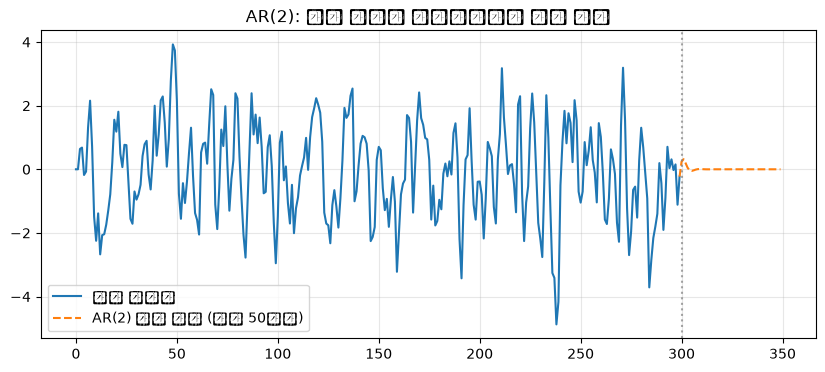

In [2]:
T = 300
x = np.zeros(T)
eps = rng.normal(0, 1, T)
for t in range(2, T):
    x[t] = 0.9 * x[t - 1] - 0.4 * x[t - 2] + eps[t]   # 진짜 AR(2) 계수: [0.9, -0.4]

# ── 최소제곱으로 AR 계수 추정: x_t ≈ a1·x_{t-1} + a2·x_{t-2} ──
Xlag = np.column_stack([x[1:-1], x[:-2]])   # 설명변수: [x_{t-1}, x_{t-2}]
ylag = x[2:]                                 # 종속변수: x_t
coef, *_ = np.linalg.lstsq(Xlag, ylag, rcond=None)
print("추정된 AR 계수:", np.round(coef, 3), " (실제: [0.9, -0.4])")

# ── 재귀적 다중스텝 예측: 미래 값은 '예측한 값'을 다시 입력으로 사용 ──
future = 50
xf = np.concatenate([x, np.zeros(future)])
for t in range(T, T + future):
    xf[t] = coef[0] * xf[t - 1] + coef[1] * xf[t - 2]

plt.plot(range(T), x, label="실제 시계열")
plt.plot(range(T - 1, T + future), xf[T - 1:], "--", label="AR(2) 모델 예측 (미래 50스텝)")
plt.axvline(T, color="gray", ls=":", alpha=0.7)
plt.legend(); plt.title("AR(2): 과거 값들의 선형결합으로 미래 예측"); plt.grid(alpha=0.3); plt.show()


## 2) MADE: 3차원 데이터의 "자기회귀 밀도 추정"

데이터: (x₁, x₂)는 moons 분포, x₃ = 0.3·x₁ + 노이즈인 3차원 데이터.
MADE는 가중치에 마스크를 씌워 `p(x₁,x₂,x₃) = p(x₁)·p(x₂|x₁)·p(x₃|x₁,x₂)` 형태가 **강제로** 되게 합니다.
학습은 음의 로그 우도(NLL) 최소화, 샘플링은 x₁부터 순서대로 생성하면 됩니다.


In [3]:
import torch
import torch.nn as nn

torch.manual_seed(0)
rng = np.random.default_rng(1)

# 3차원 합성 데이터 생성
n = 4000
t = rng.uniform(0, np.pi, n // 2)
m1 = np.column_stack([np.cos(t), np.sin(t)])
t2 = rng.uniform(0, np.pi, n - n // 2)
m2 = np.column_stack([1 - np.cos(t2), 0.5 - np.sin(t2)])
xy = np.vstack([m1, m2]) + rng.normal(0, 0.1, (n, 2))          # (x1, x2): moons 형태
data3 = np.column_stack([xy, 0.3 * xy[:, 0] + rng.normal(0, 0.3, n)]).astype(np.float32)
data_t = torch.tensor(data3)

d = 3      # 차원 수
H = 32     # 은닉 유닛 수

# ── MADE 마스크 설계 ──
# 입력 차원 i의 '차수(degree)'를 i+1로 정함: x1→1, x2→2, x3→3
# 은닉 차수는 [1, d-1] 범위에서 무작위 → 출력 x_k가 x_{<k}에만 의존하도록 구조적으로 보장
deg_in = torch.arange(1, d + 1)
deg_h1 = torch.randint(1, d, (H,))
deg_h2 = torch.randint(1, d, (H,))
deg_out = torch.arange(1, d + 1)

def mask_matrix(m_out, m_in):
    # 연결 조건: m_out[j] >= m_in[i]  (행=출력, 열=입력)
    # 이렇게 하면 출력 차수 k는 입력 차수 < k인 것들에만 연결 → AR 성질 강제
    return (m_out.unsqueeze(1) >= m_in.unsqueeze(0)).float()

class MaskedLinear(nn.Module):
    """가중치 행렬에 마스크를 곱해 '미래 → 과거' 정보 흐름을 차단"""
    def __init__(self, m_in, m_out):
        super().__init__()
        self.weight = nn.Parameter(torch.randn(len(m_out), len(m_in)) * 0.1)
        self.bias = nn.Parameter(torch.zeros(len(m_out)))
        self.register_buffer("mask", mask_matrix(m_out, m_in))

    def forward(self, x):
        return (x @ (self.weight * self.mask).T) + self.bias

class MADE(nn.Module):
    """각 차원마다 가우시안의 (평균, log표준편차)를 출력 → 총 2*d개 출력"""
    def __init__(self):
        super().__init__()
        self.l1 = MaskedLinear(deg_in, deg_h1)
        self.l2 = MaskedLinear(deg_h1, deg_h2)
        self.out = MaskedLinear(deg_h2, torch.cat([deg_out, deg_out]))  # [mu용 차수, log_std용 차수]

    def forward(self, x):
        h = torch.relu(self.l1(x))
        h = torch.relu(self.l2(h))
        out = self.out(h)
        mu, log_std = out[:, :d], out[:, d:]
        return mu, torch.clamp(log_std, -5, 2)   # log_std 범위 제한 (수치 안정성)

model = MADE()
opt = torch.optim.Adam(model.parameters(), lr=1e-3)


In [4]:
# ── 학습: AR 분해에 따른 가우시안 NLL 최소화 ──
# NLL = Σᵢ [ 0.5·((xᵢ-μᵢ)/σᵢ)² + log σᵢ + 0.5·log(2π) ]
for ep in range(400):
    opt.zero_grad()
    mu, log_std = model(data_t)
    nll = (0.5 * ((data_t - mu) / torch.exp(log_std)) ** 2
           + log_std + 0.5 * np.log(2 * np.pi)).sum(dim=1).mean()
    nll.backward()
    opt.step()
    if (ep + 1) % 100 == 0:
        print(f"에포크 {ep+1}: NLL = {nll.item():.3f}")


에포크 100: NLL = 1.576
에포크 200: NLL = -2.436


에포크 300: NLL = -3.977
에포크 400: NLL = -5.264


/tmp/ipykernel_103168/1453131039.py:18: UserWarning: Glyph 49892 (\N{HANGUL SYLLABLE SIL}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_103168/1453131039.py:18: UserWarning: Glyph 51228 (\N{HANGUL SYLLABLE JE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_103168/1453131039.py:18: UserWarning: Glyph 45936 (\N{HANGUL SYLLABLE DE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_103168/1453131039.py:18: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_103168/1453131039.py:18: UserWarning: Glyph 53552 (\N{HANGUL SYLLABLE TEO}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_103168/1453131039.py:18: UserWarning: Glyph 44032 (\N{HANGUL SYLLABLE GA}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_103168/1453131039.py:18: UserWarning: Glyp

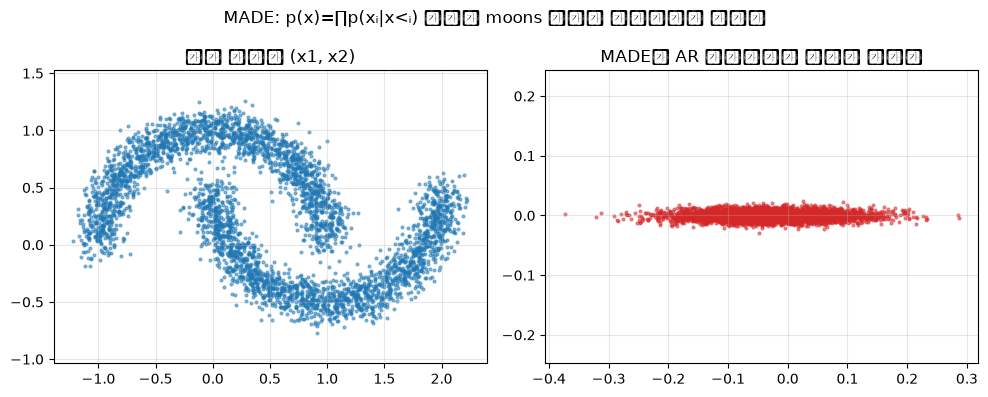

In [5]:
# ── AR 샘플링: x1을 먼저 뽑고, 그 값으로 x2를, ... 순서대로 생성 ──
with torch.no_grad():
    samples = torch.zeros(n, d)
    for i in range(d):
        mu, log_std = model(samples)
        # 마스크 덕분에 mu[:, i]는 samples[:, :i]에만 의존 → 지금까지 생성된 값만 사용
        samples[:, i] = mu[:, i] + torch.exp(log_std[:, i]) * torch.randn(n)

# 실제 데이터 vs 모델이 생성한 샘플 비교 (x1-x2 평면 투영)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(data3[:, 0], data3[:, 1], s=4, alpha=0.5)
axes[0].set_title("실제 데이터 (x1, x2)")
axes[1].scatter(samples[:, 0], samples[:, 1], s=4, alpha=0.5, c="tab:red")
axes[1].set_title("MADE가 AR 샘플링으로 생성한 데이터")
for ax in axes:
    ax.axis("equal"); ax.grid(alpha=0.3)
plt.suptitle("MADE: p(x)=∏p(xᵢ|x<ᵢ) 구조로 moons 분포를 성공적으로 모델링")
plt.tight_layout(); plt.show()


## ✅ 정리 — 이 시리즈의 마지막!

- **AR(자기회귀)**: `p(x) = ∏ p(xᵢ | x<ᵢ)` —과거로 미래를 예측. AR(p) 시계열부터 시작해서
- **MADE**는 마스크로 이 구조를 강제한 밀도 추정 모델 → 샘플링이 "순차 생성"으로 자연스럽게 가능
- 현대의 **GPT도 거대한 AR 모델**: "이전 토큰들로 다음 토큰 예측"을 반복해 텍스트를 생성
- 다른 생성 축: GAN(07), VAE, Diffusion — 관심 있으면 확장해보세요!

### 🎓 전체 로드맵 복습
| 파일 | 알고리즘 | 한 줄 요약 |
|---|---|---|
| 01 | Perceptron / ADALINE | 가중치 갱신 규칙의 시작, 선형 분리 한계 |
| 02 | MLP | 은닉층 + 역전파로 비선형 문제 해결 |
| 03 | RBM | 에너지 기반 생성 모델, CD-1 |
| 04 | CNN | 합성곱으로 이미지 특징 추출 |
| 05 | RNN/LSTM/GRU | 순환 구조로 시퀀스 처리 |
| 06 | GNN (GCN) | 그래프에서 메시지 패싱 |
| 07 | GAN | 생성자-판별자 적대 학습 |
| 08 | Transformer | 셀프 어тен션으로 전역 문맥 모델링 |
| 09 | AR / MADE | 자기회귀적 생성 (GPT의 원리) |
